# Setup

In [ ]:
!apt-get update
!apt-get install -y poppler-utils
!pip install torch torchvision transformers pdf2image pillow timm easyocr opencv-python-headless matplotlib datasets sentencepiece


Hit:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:3 https://packages.cloud.google.com/apt gcsfuse-jammy InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:5 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:8 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: https://packages.cloud.google.com/apt/dists/gcsfuse-jammy/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for deta

# PDF to Image conversion

In [ ]:
import os.path
from pdf2image import convert_from_path

# Convert PDF to an image
pdf_path = "/content/2025-01-07.pdf"  # Replace with your file path
images = convert_from_path(pdf_path, dpi=300)  # Convert at 300 DPI for clarity

# Save the first page as an image
images[0].save("/content/sample_page.png", "PNG")
print("PDF page saved as image.")

PDF page saved as image.


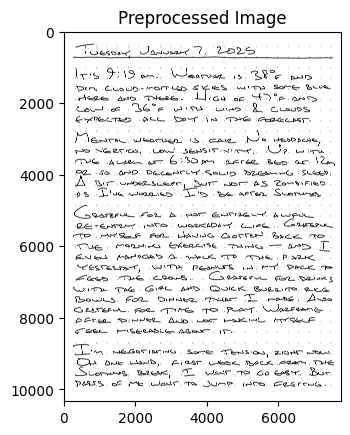

In [ ]:
from PIL import Image

# Load your handwriting image
image_path = "/content/sample_page.png"
image = Image.open(image_path).convert("RGB")  # Convert to RGB (required by TrOCR)

import matplotlib.pyplot as plt
plt.imshow(image, cmap="gray")
plt.title("Preprocessed Image")
plt.show()


# Attempting to filter out the grey dot-grid

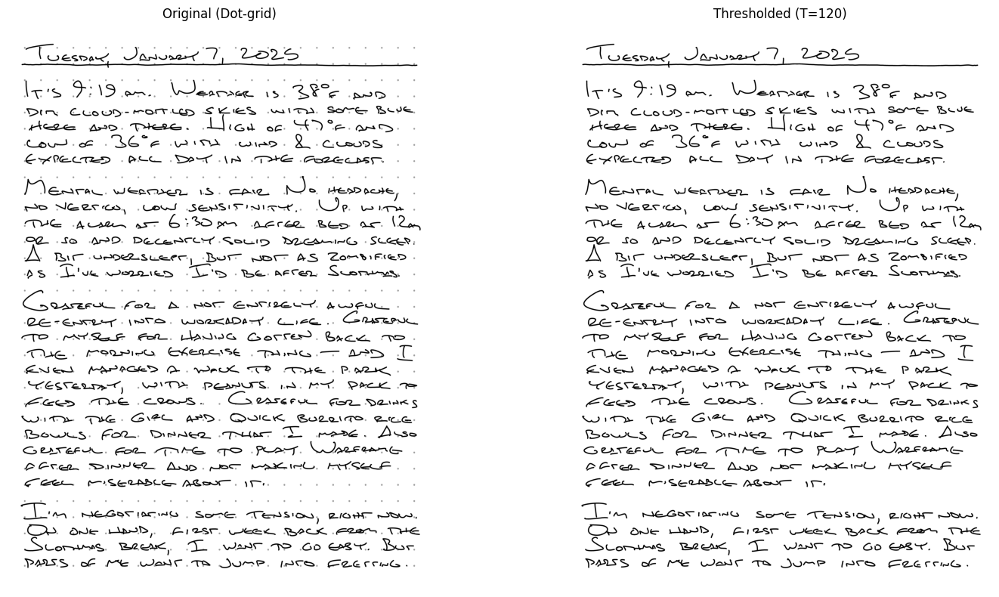

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1) Load the original image (with dot-grid background)
image_path = "/content/sample_page.png"  # Adjust path as needed
image_bgr = cv2.imread(image_path)
if image_bgr is None:
    raise ValueError("Could not load image. Check the path or filename.")

# Convert to grayscale for easier processing
image_gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# 2) Apply threshold
#    - If your handwriting is quite dark, you can use a threshold ~150-180
#      so that the lighter dots get filtered out.
thresh_value = 120
_, thresh = cv2.threshold(image_gray, thresh_value, 255, cv2.THRESH_BINARY)


cv2.imwrite("/content/my_journal_page_thresholded.png", thresh)

# 3) Morphological opening to remove small dots
#    - If the dot size is small, a small kernel (2x2, 3x3) may help.
#kernel = np.ones((12, 12), np.uint8)
#opened = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)

# 4) Display the results side by side in Colab

# Convert the original BGR image to RGB for display
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Original image
axes[0].imshow(image_rgb)
axes[0].set_title("Original (Dot-grid)")
axes[0].axis("off")

# Thresholded image
axes[1].imshow(thresh, cmap="gray")
axes[1].set_title(f"Thresholded (T={thresh_value})")
axes[1].axis("off")

# Opened image
#axes[2].imshow(opened, cmap="gray")
#axes[2].set_title("After Morphological Opening")
#axes[2].axis("off")

plt.tight_layout()
plt.show()


# Using EasyOCR for OCR baseline and to find bounding boxen for words

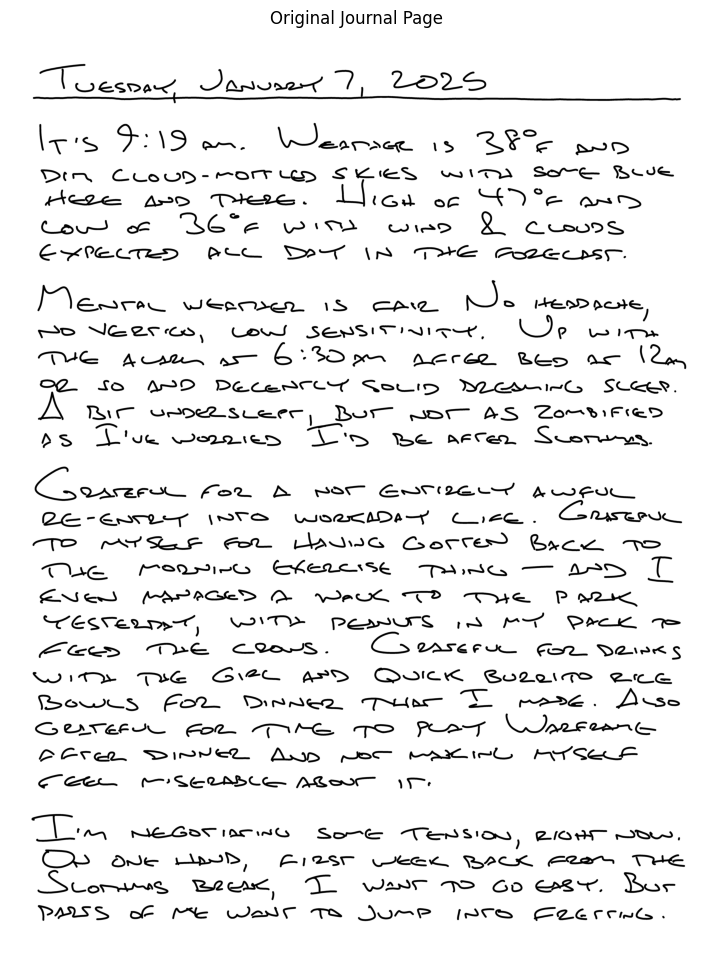

In [ ]:
import easyocr
import cv2
import matplotlib.pyplot as plt

#image_path = '/content/sample_page.png'
image_path = '/content/my_journal_page_thresholded.png'

# Load the image with OpenCV (for visualization)
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR -> RGB

plt.figure(figsize=(10, 12))
plt.imshow(image)
plt.title("Original Journal Page")
plt.axis("off")
plt.show()


In [ ]:
# Initialize the EasyOCR Reader
# You can specify language(s). "en" for English.
reader = easyocr.Reader(['en'], gpu=True)  # If Colab has GPU enabled

# Run OCR
results = reader.readtext(image_path)
# 'results' is a list of [ [bbox, text, confidence], ... ]


In [ ]:
for (bbox, text, confidence) in results:
    print("Detected text:", text, "| Confidence:", confidence)


Detected text: 2~3x /_ | Confidence: 0.007732207537835339
Detected text: 2225 | Confidence: 0.43969717621803284
Detected text: 9.19 | Confidence: 0.6963174939155579
Detected text: QX . | Confidence: 0.03313911333680153
Detected text: LJaarAar | Confidence: 0.14391111718776026
Detected text: 1 $ | Confidence: 0.7458617901561689
Detected text: 3p26 | Confidence: 0.06389938294887543
Detected text: AJD | Confidence: 0.0795637161382818
Detected text: P(7 | Confidence: 0.32816677195858407
Detected text: CLouD -FonL) | Confidence: 0.07258066137033761
Detected text: Un | ~ | Confidence: 0.08587892244552982
Detected text: Sce | Confidence: 0.35792295886009445
Detected text: ScJc | Confidence: 0.10835769027471542
Detected text: xa2 e | Confidence: 0.09625554275640709
Detected text: 4-p | Confidence: 0.04888978528316157
Detected text: T4263 | Confidence: 0.23539594007563083
Detected text: fkes | Confidence: 0.07163853943347931
Detected text: Oc | Confidence: 0.30818003835785623
Detected text: 4 )

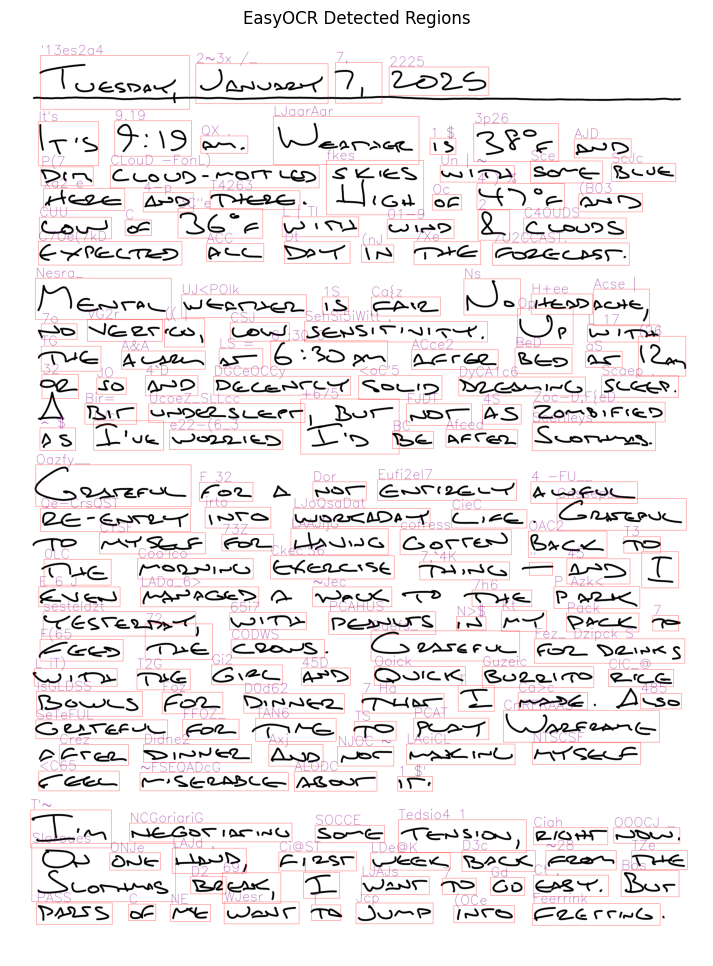

In [ ]:
import numpy as np
annotated_image = image.copy()

for (bbox, text, confidence) in results:
    # bbox is typically a list of four corner points
    top_left = (int(bbox[0][0]), int(bbox[0][1]))
    bottom_right = (int(bbox[2][0]), int(bbox[2][1]))

    # Draw bounding box
    cv2.rectangle(
        annotated_image,
        top_left,
        bottom_right,
        (255, 0, 0), 2
    )
    # Put recognized text above the box
    cv2.putText(
        annotated_image,
        text,
        (top_left[0], top_left[1] - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        5,
        (128, 0, 128),
        2,
        cv2.LINE_AA
    )

plt.figure(figsize=(10,12))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("EasyOCR Detected Regions")
plt.show()

# Trying Tesseract for OCR baseline

In [ ]:
!sudo apt-get update
!sudo apt-get install tesseract-ocr
!pip install pytesseract


Hit:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:3 https://packages.cloud.google.com/apt gcsfuse-jammy InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:7 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:8 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: https://packages.cloud.google.com/apt/dists/gcsfuse-jammy/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for deta

In [ ]:
import pytesseract
from PIL import Image

image_path = '/content/my_journal_page_thresholded.png'
text_result = pytesseract.image_to_string(Image.open(image_path), lang='eng')
print(text_result)

TT Geewae TD arsose/’ 7, 2O2SD

lv 'S d: \S aw. \eanseg. LS OX eS SW
Dim Cruseods-rarreeays SHIeQ wim Some Bove
Meee APs Pera. ‘(Ga o¢ KD°e ans
CamnH co “Gre LP vO CI 1-D Q- Co USOD GY
CK9ECTED AOC DAT IR THE Sez ease.

I’ eescan Weemsen 1S CAW, We EDD DEE,
To Neer cs, CEeEnwsS Se, SStTnivsg-t. De Ll - IT.
A1Voe Acree as— G: SO pr nEeEre2 Res ac oa
C2 S060 ARO BDEcer® Tr Asuin BD2HKoiwG SCE.
Tu UMoe2 SLKeT | Bor wor AS “ComvdiF ted
AS Vile VL PIS292N SS Tis RWG KFC SQ, Qos reyes,

Ccacero Fou KR PST EG oviz2errw £OE0UC_
Qe -eGrsvery yreve VWeecltda-y Co#uec. RASS PIC_
TO mwrGer eeu LHbAYYHG Gorte~ BGaowe ro
Tt se TSO YPM CHEN .SE Taoescy aT ARPT a
GSSeus -APAGEDS OD Wem sTO MH<— P oot
WESTEI TET, WITTY Pears iA eT PreK we
EK Gees Arba CVe-S. Cy ZASEFYH Coor2_ DAK §
WI tTye TG GiFeQe 229 OvicK GBo2eritTo eee
ISouILyK FoO2 WMrreq Tia “LM ee. Axvse
C5 QAT GFUON Cor (Kae TCO pray \VODA2E een (CR
CPEren. SDiPrYee Asy sce Ke“s~sxectel MYCE

Co Ce. §—-SE?CABCRH ARoor 1T-.

Tiny Me saree Sone 

# Trying to visualize Tesseract's word detection

In [ ]:
# Install Tesseract system package (Ubuntu/Debian)
!sudo apt-get update
!sudo apt-get install tesseract-ocr

# Install python wrapper
!pip install pytesseract opencv-python-headless matplotlib

Hit:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:2 https://packages.cloud.google.com/apt gcsfuse-jammy InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:5 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:8 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: https://packages.cloud.google.com/apt/dists/gcsfuse-jammy/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for deta

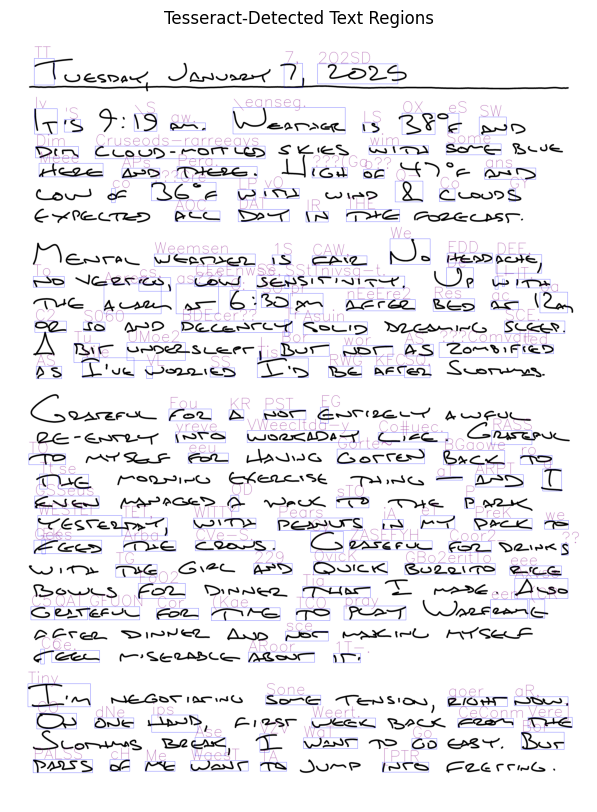

In [ ]:
import pytesseract
from pytesseract import Output
import cv2
import matplotlib.pyplot as plt

# Specify your image path
image_path = "/content/my_journal_page_thresholded.png"

# Load with OpenCV (BGR format)
image_bgr = cv2.imread(image_path)
if image_bgr is None:
    raise ValueError("Could not load image. Check file path or extension.")

# Perform OCR with bounding box data
data = pytesseract.image_to_data(image_bgr, output_type=Output.DICT)

# data is a dict with keys like:
# ['level', 'page_num', 'block_num', 'par_num', 'line_num', 'word_num',
#  'left', 'top', 'width', 'height', 'conf', 'text']

# Copy the original for annotation
annotated = image_bgr.copy()

for i in range(len(data["text"])):
    x = data["left"][i]
    y = data["top"][i]
    w = data["width"][i]
    h = data["height"][i]
    text = data["text"][i]
    conf = int(data["conf"][i])

    # Ignore empty or low-confidence text
    if conf > 0 and text.strip() != "":
        # Draw a bounding box
        cv2.rectangle(annotated, (x, y), (x + w, y + h), (255, 0, 0), 2)

        # Put recognized text above the box
        font_scale = 7  # Adjust for bigger text
        cv2.putText(
            annotated,
            text,
            (x, y - 10),  # slightly above the top-left
            cv2.FONT_HERSHEY_SIMPLEX,
            font_scale,
            (128, 0, 128),
            2,
            cv2.LINE_AA
        )

annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 10))
plt.imshow(annotated_rgb)
plt.title("Tesseract-Detected Text Regions")
plt.axis("off")
plt.show()

# Attempt to combine EasyOCR for bounding box detection and TrOCR for word recognition

In [ ]:
!pip install easyocr opencv-python-headless matplotlib transformers datasets sentencepiece pillow


In [ ]:
import easyocr
import cv2
import matplotlib.pyplot as plt
import os

import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image


In [ ]:
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available())


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten").to(device)


Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.47.1"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder

In [ ]:
image_path = "/content/my_journal_page_thresholded.png"
original_bgr = cv2.imread(image_path)
if original_bgr is None:
    raise ValueError("Could not load image. Check the path.")

# EasyOCR returns a list of [ [bbox, text, confidence], ... ]
# bbox is a list of 4 corner points
results = reader.readtext(image_path)
print(f"Found {len(results)} text regions via EasyOCR.")

Found 177 text regions via EasyOCR.


In [ ]:
recognized_data = []  # will hold tuples: (x_min, y_min, x_max, y_max, recognized_text)

for i, (bbox, e_text, e_conf) in enumerate(results):
    # bbox is a list of four corner points: [(x1, y1), (x2, y2), (x3, y3), (x4, y4)]
    x_coords = [pt[0] for pt in bbox]
    y_coords = [pt[1] for pt in bbox]
    x_min, x_max = int(min(x_coords)), int(max(x_coords))
    y_min, y_max = int(min(y_coords)), int(max(y_coords))

    # 1) Crop the region from the original image
    crop_bgr = original_bgr[y_min:y_max, x_min:x_max]

    # 2) Convert BGR -> RGB for PIL
    crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(crop_rgb)

    # 3) Use TrOCR to recognize this crop
    inputs = processor(images=pil_img, return_tensors="pt").to(device)
    with torch.no_grad():
        generated_ids = model.generate(inputs.pixel_values)
    trocr_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

    # 4) Store the bounding box and recognized text
    recognized_data.append((x_min, y_min, x_max, y_max, trocr_text))

    # Print or log the recognized text for debugging
    print(f"Detected region {i}: TrOCR => '{trocr_text}'")


Detected region 0: TrOCR => 'January'
Detected region 1: TrOCR => '2025'
Detected region 2: TrOCR => '9. 1 9'
Detected region 3: TrOCR => 'pp .'
Detected region 4: TrOCR => 'whearser .'
Detected region 5: TrOCR => '1 S'
Detected region 6: TrOCR => '3&8'
Detected region 7: TrOCR => 'AN D'
Detected region 8: TrOCR => 'Dr. R.'
Detected region 9: TrOCR => '( LLOOD - MOST LED'
Detected region 10: TrOCR => 'W.I 12 )'
Detected region 11: TrOCR => 'some'
Detected region 12: TrOCR => 'B.CUE'
Detected region 13: TrOCR => 'H CEC'
Detected region 14: TrOCR => 'ARD'
Detected region 15: TrOCR => 'there .'
Detected region 16: TrOCR => 'IT.C.'
Detected region 17: TrOCR => '0 f'
Detected region 18: TrOCR => '4 7 0/'
Detected region 19: TrOCR => 'Axers D'
Detected region 20: TrOCR => 'courl'
Detected region 21: TrOCR => 'of'
Detected region 22: TrOCR => '36. "'
Detected region 23: TrOCR => 'W.P.P.'
Detected region 24: TrOCR => 'W. 1/SD'
Detected region 25: TrOCR => '2.'
Detected region 26: TrOCR => 'C C

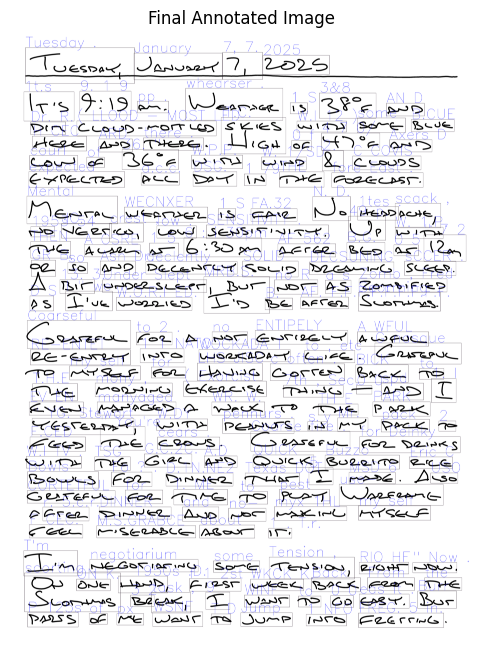

In [ ]:
# This block reads recognized_data and draws bounding boxes & text on a copy of the original image

annotated_bgr = original_bgr.copy()

for (x_min, y_min, x_max, y_max, text) in recognized_data:
    # Draw bounding box
    cv2.rectangle(annotated_bgr, (x_min, y_min), (x_max, y_max), (16, 0, 16), 2)

    # Draw recognized text above the box
    cv2.putText(
        annotated_bgr,
        text,
        (x_min, y_min - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        8.0,    # font scale
        (255, 0, 0),
        2,
        cv2.LINE_AA
    )

# Now annotated_bgr has all boxes and text drawn
# (Optional) convert for display or save
annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12,8))
plt.imshow(annotated_rgb)
plt.axis("off")
plt.title("Final Annotated Image")
plt.show()


# Prepare a data set for fine tuning from bounding boxes using EasyOCR and TrOCR

In [ ]:
import os
import csv

output_folder = "word_crops"
os.makedirs(output_folder, exist_ok=True)  # create folder if doesn't exist

csv_path = "recognized_words.csv"

# If you want a fresh CSV each run, overwrite. Otherwise "append" mode.
# We'll create a header row if it doesn't exist:
write_header = not os.path.exists(csv_path)
with open(csv_path, 'a', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    if write_header:
        writer.writerow(["crop_filename", "recognized_text"])

recognized_data = []  # to hold (crop_path, recognized_text)

for i, (bbox, e_text, e_conf) in enumerate(results):
    # Extract bounding box
    x_coords = [pt[0] for pt in bbox]
    y_coords = [pt[1] for pt in bbox]
    x_min, x_max = int(min(x_coords)), int(max(x_coords))
    y_min, y_max = int(min(y_coords)), int(max(y_coords))

    # Crop from original
    crop_bgr = original_bgr[y_min:y_max, x_min:x_max]

    # Convert BGR -> RGB
    crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(crop_rgb)

    # TrOCR recognition
    inputs = processor(images=pil_img, return_tensors="pt").to(device)
    with torch.no_grad():
        generated_ids = model.generate(inputs.pixel_values)
    trocr_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

    # Save the crop as a PNG file
    crop_filename = f"word_{i}.png"  # e.g., word_0.png, word_1.png, ...
    crop_path = os.path.join(output_folder, crop_filename)
    pil_img.save(crop_path)

    # Print for debugging
    print(f"Detected region {i}: TrOCR => '{trocr_text}', saved to {crop_path}")

    # Append to our recognized_data list
    recognized_data.append((crop_path, trocr_text))

with open(csv_path, 'a', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    for crop_path, text in recognized_data:
        writer.writerow([crop_path, text])


Detected region 0: TrOCR => 'January', saved to word_crops/word_0.png
Detected region 1: TrOCR => '2025', saved to word_crops/word_1.png
Detected region 2: TrOCR => '9. 1 9', saved to word_crops/word_2.png
Detected region 3: TrOCR => 'pp .', saved to word_crops/word_3.png
Detected region 4: TrOCR => 'whearser .', saved to word_crops/word_4.png
Detected region 5: TrOCR => '1 S', saved to word_crops/word_5.png
Detected region 6: TrOCR => '3&8', saved to word_crops/word_6.png
Detected region 7: TrOCR => 'AN D', saved to word_crops/word_7.png
Detected region 8: TrOCR => 'Dr. R.', saved to word_crops/word_8.png
Detected region 9: TrOCR => '( LLOOD - MOST LED', saved to word_crops/word_9.png
Detected region 10: TrOCR => 'W.I 12 )', saved to word_crops/word_10.png
Detected region 11: TrOCR => 'some', saved to word_crops/word_11.png
Detected region 12: TrOCR => 'B.CUE', saved to word_crops/word_12.png
Detected region 13: TrOCR => 'H CEC', saved to word_crops/word_13.png
Detected region 14: TrO

# Try using Gradio to build a quick dataset labelling tool

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import csv
import os
from PIL import Image

# --- 1) FILE PATHS ---
CSV_INPUT = "recognized_words.csv"                # original file (read-only)
IMAGE_FOLDER = "word_crops"                       # folder with cropped images
CSV_OUTPUT = "recognized_words_labeled.csv"       # new file to write updated labels

# --- 2) LOAD SAMPLES ---
samples = []  # will hold dicts: {"filename": ..., "label": ...}

with open(CSV_INPUT, 'r', encoding='utf-8') as f:
    reader = csv.DictReader(f)
    for row in reader:
        samples.append({
            "filename": row["crop_filename"],
            "label": row["recognized_text"]
        })

# We'll track the current index in Gradio state
def load_sample(idx):
    """Return (image, label, corrected_idx)."""
    # Clamp the index
    idx = max(0, min(len(samples) - 1, idx))
    sample = samples[idx]

    # Construct full image path
    img_path = os.path.join(IMAGE_FOLDER, os.path.basename(sample["filename"]))
    if os.path.exists(img_path):
        pil_img = Image.open(img_path)
    else:
        pil_img = Image.new("RGB", (300, 100), color="red")  # placeholder if missing

    return pil_img, sample["label"], idx

def handle_submit(current_label, idx):
    """
    Saves the current label in samples[idx], increments idx,
    loads the next sample. (Effectively a 'Next' triggered by pressing Enter.)
    """
    # Update in-memory label
    samples[idx]["label"] = current_label
    new_idx = idx + 1
    if new_idx >= len(samples):
        new_idx = len(samples) - 1  # stay on last if user hits Enter on last item
    return load_sample(new_idx)

def save_csv():
    """
    Writes the entire updated labels to CSV_OUTPUT.
    """
    with open(CSV_OUTPUT, 'w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(["crop_filename", "recognized_text"])
        for s in samples:
            writer.writerow([s["filename"], s["label"]])
    return f"Labels saved to {CSV_OUTPUT}."

# --- 3) BUILD GRADIO INTERFACE ---
def on_start():
    """Load the first sample on app load."""
    return load_sample(0)  # image, label, index=0

with gr.Blocks() as demo:
    gr.Markdown("# Handwriting Labeling\n**Press Enter** to save and advance to the next word.")

    state_idx = gr.State(value=0)  # track current index
    image_out = gr.Image(type="pil", label="Word Crop")
    label_box = gr.Textbox(label="Corrected Label")
    status = gr.Label()

    # Initialize the first sample when the app loads
    demo.load(on_start, inputs=None, outputs=[image_out, label_box, state_idx])

    # Pressing Enter in the text box triggers handle_submit
    label_box.submit(
        fn=handle_submit,
        inputs=[label_box, state_idx],
        outputs=[image_out, label_box, state_idx]
    )

    # A "Save CSV" button if you want to finalize to the new file
    btn_save = gr.Button("Save CSV")
    btn_save.click(
        fn=save_csv,
        inputs=[],
        outputs=status
    )

demo.launch(height=1000)


Running Gradio in a Colab notebook requires sharing enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://04522c7a55a8a100d9.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Try fine tuning TrOCR with my labelled dataset

In [ ]:
# Attempt to mitigate https://github.com/huggingface/transformers/issues/35838
!pip install transformers==4.45.2

!pip install torch torchvision jiwer datasets evaluate



  Using cached jiwer-3.1.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached evaluate-0.4.3-py3-none-any.whl.metadata (9.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 70.1 MB/s eta 0:00:00


In [ ]:
import transformers
print(transformers.__version__)

4.45.2


In [ ]:
# Verify GPU availability
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')


Using device: cuda


In [ ]:
import os
import pandas as pd
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel, Seq2SeqTrainingArguments, Seq2SeqTrainer
from datasets import Dataset
import evaluate  # Updated import
import torch
import numpy as np
import random


In [ ]:
# Define paths
images_dir = '/content/word_crops'
labels_file = '/content/recognized_words_labeled.csv'

# Load the CSV file
df = pd.read_csv(labels_file)

# Display first few entries to verify
df.head()


,crop_filename,recognized_text
0,word_crops/word_0.png,January
1,word_crops/word_1.png,2025
2,word_crops/word_2.png,9:19
3,word_crops/word_3.png,am.
4,word_crops/word_4.png,Weather


In [ ]:
# Create full image paths
df['image_path'] = df['crop_filename']

# Select relevant columns
df = df[['image_path', 'recognized_text']]

# Convert pandas DataFrame to Hugging Face Dataset
dataset = Dataset.from_pandas(df)

# Display a sample
print(dataset[0])


{'image_path': 'word_crops/word_0.png', 'recognized_text': 'January'}


In [ ]:
from transformers import logging

# Suppress warnings and info logs
logging.set_verbosity_error()

# Load processor and model
processor = TrOCRProcessor.from_pretrained('microsoft/trocr-base-handwritten')
model = VisionEncoderDecoderModel.from_pretrained('microsoft/trocr-base-handwritten')
model.to(device)


VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=False)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=False)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_fea

In [ ]:
def preprocess_function(examples):
    # Load and preprocess images
    images = [Image.open(image_path).convert("RGB") for image_path in examples['image_path']]

    # Process images
    pixel_values = processor(images=images, return_tensors="pt").pixel_values

    # Tokenize labels
    labels = processor.tokenizer(examples['recognized_text'], padding="max_length", truncation=True, max_length=32).input_ids

    # Replace padding with -100 to ignore in loss computation
    labels = [[(label if label != processor.tokenizer.pad_token_id else -100) for label in label_seq] for label_seq in labels]

    # Convert to tensor
    labels = torch.tensor(labels)

    return {"pixel_values": pixel_values, "labels": labels}


In [ ]:
# Apply the preprocessing
processed_dataset = dataset.map(preprocess_function, batched=True, remove_columns=["image_path", "recognized_text"])

# Inspect a processed sample
print(processed_dataset[0])


Map:   0%|          | 0/354 [00:00<?, ? examples/s]

{'pixel_values': [[[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 

In [ ]:
# Set a seed for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Split the dataset: 90% training, 10% validation
split_dataset = processed_dataset.train_test_split(test_size=0.1, seed=seed)
train_dataset = split_dataset['train']
eval_dataset = split_dataset['test']

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(eval_dataset)}")


Number of training samples: 318
Number of validation samples: 36


In [ ]:
training_args = Seq2SeqTrainingArguments(
    output_dir="./trocr-finetuned",
    evaluation_strategy="steps",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=10,
    predict_with_generate=True,
    logging_steps=50,        # Increased frequency for better visibility
    save_steps=500,
    eval_steps=500,
    fp16=True,               # Use mixed precision if supported
    remove_unused_columns=True,
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    report_to=["tensorboard"],  # Enable TensorBoard logging
    logging_dir="./trocr-finetuned/runs",  # Explicitly set logging directory
)


/usr/local/lib/python3.10/dist-packages/transformers/training_args.py:1545: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [ ]:
# Load WER metric using the 'evaluate' library
wer_metric = evaluate.load("wer")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    # Decode predictions
    decoded_preds = processor.batch_decode(predictions, skip_special_tokens=True)

    # Replace -100 in labels as we can't decode them
    labels = np.where(labels != -100, labels, processor.tokenizer.pad_token_id)

    # Decode labels
    decoded_labels = processor.batch_decode(labels, skip_special_tokens=True)

    # Compute WER
    wer = wer_metric.compute(predictions=decoded_preds, references=decoded_labels)

    return {"wer": wer}


In [1]:
# Check if decoder_start_token_id is set; if not, set it to eos_token_id
if model.config.decoder_start_token_id is None:
    model.config.decoder_start_token_id = processor.tokenizer.eos_token_id
    print(f"decoder_start_token_id set to eos_token_id: {model.config.decoder_start_token_id}")
else:
    print(f"decoder_start_token_id is already set to: {model.config.decoder_start_token_id}")

# Check if pad_token is defined; if not, add one
if processor.tokenizer.pad_token is None:
    processor.tokenizer.add_special_tokens({'pad_token': '<PAD>'})
    print("Added pad_token:", processor.tokenizer.pad_token)
    model.resize_token_embeddings(len(processor.tokenizer))
else:
    print("pad_token already defined as:", processor.tokenizer.pad_token)

# Set the pad_token_id in the model's configuration
model.config.pad_token_id = processor.tokenizer.pad_token_id

# Optionally, set labels_pad_token_id if it's separate (useful for loss computation)
model.config.labels_pad_token_id = processor.tokenizer.pad_token_id

print(f"pad_token_id set to: {model.config.pad_token_id}")
print(f"labels_pad_token_id set to: {model.config.labels_pad_token_id}")
print(f"Pad token: {processor.tokenizer.decode(model.config.pad_token_id)}")


NameError: name 'model' is not defined

In [ ]:
from transformers import EarlyStoppingCallback

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    tokenizer=processor,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],  # Stops training if no improvement in 3 evaluations
)


In [ ]:
# Load TensorBoard extension
%load_ext tensorboard

# Start TensorBoard
%tensorboard --logdir ./trocr-finetuned/runs


<IPython.core.display.Javascript object>

In [ ]:
trainer.train()


{'loss': 0.6117, 'grad_norm': 12.634262084960938, 'learning_rate': 1.0100000000000002e-05, 'epoch': 5.0}
{'loss': 0.2578, 'grad_norm': 8.282362937927246, 'learning_rate': 1.0000000000000001e-07, 'epoch': 10.0}
{'train_runtime': 940.3823, 'train_samples_per_second': 3.382, 'train_steps_per_second': 0.213, 'train_loss': 0.4347182083129883, 'epoch': 10.0}


TrainOutput(global_step=200, training_loss=0.4347182083129883, metrics={'train_runtime': 940.3823, 'train_samples_per_second': 3.382, 'train_steps_per_second': 0.213, 'train_loss': 0.4347182083129883, 'epoch': 10.0})

In [ ]:
# Save the model and processor
trainer.save_model("./trocr-finetuned")
processor.save_pretrained("./trocr-finetuned")


[]

In [ ]:
# Reload the fine-tuned model and processor
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

processor = TrOCRProcessor.from_pretrained("./trocr-finetuned")
model = VisionEncoderDecoderModel.from_pretrained("./trocr-finetuned")
model.to(device)

# Function to predict text from image
def predict(image_path):
    image = Image.open(image_path).convert("RGB")
    pixel_values = processor(images=image, return_tensors="pt").pixel_values
    pixel_values = pixel_values.to(device)

    generated_ids = model.generate(pixel_values)
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_text

# Test on a few samples from the validation set
sample_indices = random.sample(range(len(eval_dataset)), 20)
for idx in sample_indices:
    sample = eval_dataset[idx]
    image_path = df['image_path'][idx]
    true_text = df['recognized_text'][idx]
    predicted_text = predict(image_path)
    print(f"Image: {image_path}")
    print(f"True Text: {true_text}")
    print(f"Predicted Text: {predicted_text}\n")


Image: word_crops/word_32.png
True Text: forecast
Predicted Text: forecast

Image: word_crops/word_1.png
True Text: 2025
Predicted Text: 2025

Image: word_crops/word_12.png
True Text: blue
Predicted Text: B.CUE

Image: word_crops/word_26.png
True Text: clouds
Predicted Text: C COVIS

Image: word_crops/word_14.png
True Text: and
Predicted Text: and

Image: word_crops/word_31.png
True Text: the
Predicted Text: the

Image: word_crops/word_18.png
True Text: 47°F
Predicted Text: 4 7 0/

Image: word_crops/word_8.png
True Text: dim
Predicted Text: Dr. R.

Image: word_crops/word_25.png
True Text: &
Predicted Text: &

Image: word_crops/word_0.png
True Text: January
Predicted Text: January

Image: word_crops/word_24.png
True Text: wind
Predicted Text: wind

Image: word_crops/word_5.png
True Text: is
Predicted Text: is

Image: word_crops/word_22.png
True Text: 36°F
Predicted Text: 36°F

Image: word_crops/word_13.png
True Text: here
Predicted Text: H CEC

Image: word_crops/word_10.png
True Text: w

In [ ]:
# Evaluate on the validation set
eval_results = trainer.evaluate()

print(f"Validation WER: {eval_results}")


/usr/local/lib/python3.10/dist-packages/transformers/generation/utils.py:1220: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


{'eval_loss': 2.903343439102173, 'eval_wer': 1.0185185185185186, 'eval_runtime': 11.156, 'eval_samples_per_second': 3.227, 'eval_steps_per_second': 0.269, 'epoch': 10.0}
Validation WER: {'eval_loss': 2.903343439102173, 'eval_wer': 1.0185185185185186, 'eval_runtime': 11.156, 'eval_samples_per_second': 3.227, 'eval_steps_per_second': 0.269, 'epoch': 10.0}


# Try my finetuned TrOCR model on my original document with EasyOCR bounding boxes

In [ ]:
# Step 1: Install Required Libraries
#!pip install easyocr
#!pip install --upgrade transformers
#!pip install --upgrade torch torchvision
#!pip install matplotlib

# Step 2: Import Necessary Modules
import easyocr
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
import torch
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import os

In [ ]:
# Step 3: Initialize EasyOCR and TrOCR Models
# Initialize EasyOCR reader
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available())

# Load the finetuned TrOCR model and processor
model_path = "./trocr-finetuned"  # Ensure this path is correct
processor = TrOCRProcessor.from_pretrained(model_path)
model = VisionEncoderDecoderModel.from_pretrained(model_path)

# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

print(f"Model loaded to {device}")

Model loaded to cuda


In [ ]:
# Step 4: Detect Words Using EasyOCR
# Define the path to your full-page image
image_path = "/content/my_journal_page_thresholded.png"

# Open the image using PIL
image = Image.open(image_path).convert("RGB")

# Perform word detection using EasyOCR
# results: list of tuples (bounding_box, text, confidence)
results = reader.readtext(image_path, detail=1, paragraph=False)

print(f"Detected {len(results)} words.")

Detected 177 words.


In [ ]:
# Step 5: Sort Bounding Boxes in Reading Order
def sort_bounding_boxes(results):
    """
    Sort bounding boxes from top to bottom and left to right.
    """
    # Extract bounding boxes and associated data
    data = []
    for result in results:
        bbox = result[0]  # Bounding box
        text = result[1]  # Detected text (unused)
        conf = result[2]  # Confidence (optional)
        # Calculate the average y-coordinate for top of the box
        avg_y = np.mean([point[1] for point in bbox])
        data.append((bbox, avg_y))

    # Sort primarily by avg_y (top to bottom), then by x-coordinate (left to right)
    sorted_data = sorted(data, key=lambda x: (x[1], x[0][0][0]))
    sorted_bboxes = [item[0] for item in sorted_data]
    return sorted_bboxes

sorted_bboxes = sort_bounding_boxes(results)

In [ ]:
# Step 6: Extract Word Images and Recognize Text with TrOCR
def extract_word_image(image, bbox, padding=5):
    """
    Extracts a word image from the full-page image using the bounding box.
    Adds padding to include surrounding pixels.
    """
    # Unpack bounding box coordinates
    x1, y1 = bbox[0]
    x2, y2 = bbox[2]

    # Add padding
    x1 = max(int(x1) - padding, 0)
    y1 = max(int(y1) - padding, 0)
    x2 = min(int(x2) + padding, image.width)
    y2 = min(int(y2) + padding, image.height)

    # Crop the image
    cropped_image = image.crop((x1, y1, x2, y2))

    return cropped_image

def recognize_text(word_image, processor, model, device):
    """
    Recognizes text from a word image using TrOCR.
    """
    # Preprocess the image
    pixel_values = processor(images=word_image, return_tensors="pt").pixel_values
    pixel_values = pixel_values.to(device)

    # Generate token IDs
    with torch.no_grad():
        generated_ids = model.generate(pixel_values)

    # Decode the token IDs to get the recognized text
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

    return generated_text

# Initialize list to hold recognized texts
recognized_texts = []

# Iterate over sorted bounding boxes
for bbox in sorted_bboxes:
    # Extract word image
    word_img = extract_word_image(image, bbox, padding=5)

    # Recognize text using TrOCR
    text = recognize_text(word_img, processor, model, device)

    recognized_texts.append(text)

# Combine recognized texts into a single string
final_text = ' '.join(recognized_texts)

print("Recognized Text:\n")
print(final_text)

/usr/local/lib/python3.10/dist-packages/transformers/generation/utils.py:1220: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Recognized Text:

2025 Tuesday, 7, January 9:19 Weather 3&8 It's am. is and some B.CUE with Dr. R. cloud-mottled skies
High 47°F H CEC there and of Axers D 36°F & with of courl C COVIS wind all day expected the in forecast No Mental 1tes . is weather fair scack , Up vert no sensitivity. low crest , with 6:30am 12am at THEN 0 5 after A CSRE B.G. and declently so dreaming GR B. sCCER . SOLID zombified Under Slept bit a s no R , but
I'd I've Slothmas. after as worried B. Grateful entirely no for A WFUL Grateful workaday into life re-entry having gotten for myself back to exercise - morning 1. I thing and the even manyaged walk park TH E with my pack pennurs . in to yesterday the Grateful cears . feed for Deinky girl quick and burrito with rice TSG I made USO for Texas DOT D.1N.NE2 Bowls Warframe pest grateful for time to DINNER myself myx 1HL fter and no- feel about M.S.GRABCE it. I'm negotiarium some " Now . tension, RIO HF the From hand, back one first week On one
Slothmas Burr 9 br wan

In [ ]:
# Step 7: Assemble Recognized Text into a Document
# Save the final text to a .txt file
output_text_path = "/content/recognized_journal_page.txt"

with open(output_text_path, "w") as f:
    f.write(final_text)

print(f"Recognized text saved to {output_text_path}")

Recognized text saved to /content/recognized_journal_page.txt


In [ ]:
def visualize_predictions(image, sorted_bboxes, recognized_texts, font_size=100, padding=10):
    """
    Draws bounding boxes and recognized text on the image with increased text size.

    Parameters:
    - image (PIL.Image): The original image.
    - sorted_bboxes (list): List of bounding boxes sorted in reading order.
    - recognized_texts (list): List of recognized texts corresponding to the bounding boxes.
    - font_size (int): Size of the font for the recognized text.
    - padding (int): Padding around the text background for better visibility.
    """
    from PIL import ImageDraw, ImageFont
    import matplotlib.pyplot as plt
    import os

    # Convert image to RGB if not already
    image = image.convert("RGB")
    draw = ImageDraw.Draw(image)

    font = ImageFont.load_default(size=font_size)

    # Iterate over bounding boxes and recognized texts
    for bbox, text in zip(sorted_bboxes, recognized_texts):
        # Draw bounding box
        draw.line(
            [tuple(bbox[0]), tuple(bbox[1]), tuple(bbox[2]), tuple(bbox[3]), tuple(bbox[0])],
            fill="red",
            width=2
        )

        # Calculate position for text (top-left corner of the bounding box)
        x, y = bbox[0]

        # Calculate text size using ImageFont.getbbox or ImageFont.getsize for compatibility
        if hasattr(font, "getbbox"):
            text_bbox = font.getbbox(text)
            text_width = text_bbox[2] - text_bbox[0]
            text_height = text_bbox[3] - text_bbox[1]
        else:
            # Fallback for older Pillow versions
            text_width, text_height = draw.textsize(text, font=font)

        # Adjust y position to place text above the bounding box
        y_text = y - text_height - padding if y - text_height - padding > 0 else y + padding

        # Draw text background rectangle
        draw.rectangle([x, y_text, x + text_width, y_text + text_height], fill="yellow")

        # Draw text
        draw.text((x, y_text), text, fill="black", font=font)

    # Display the image with increased figure size for better visibility
    plt.figure(figsize=(20, 20))  # Increased from (15, 15) to (20, 20)
    plt.imshow(image)
    plt.axis('off')
    plt.show()


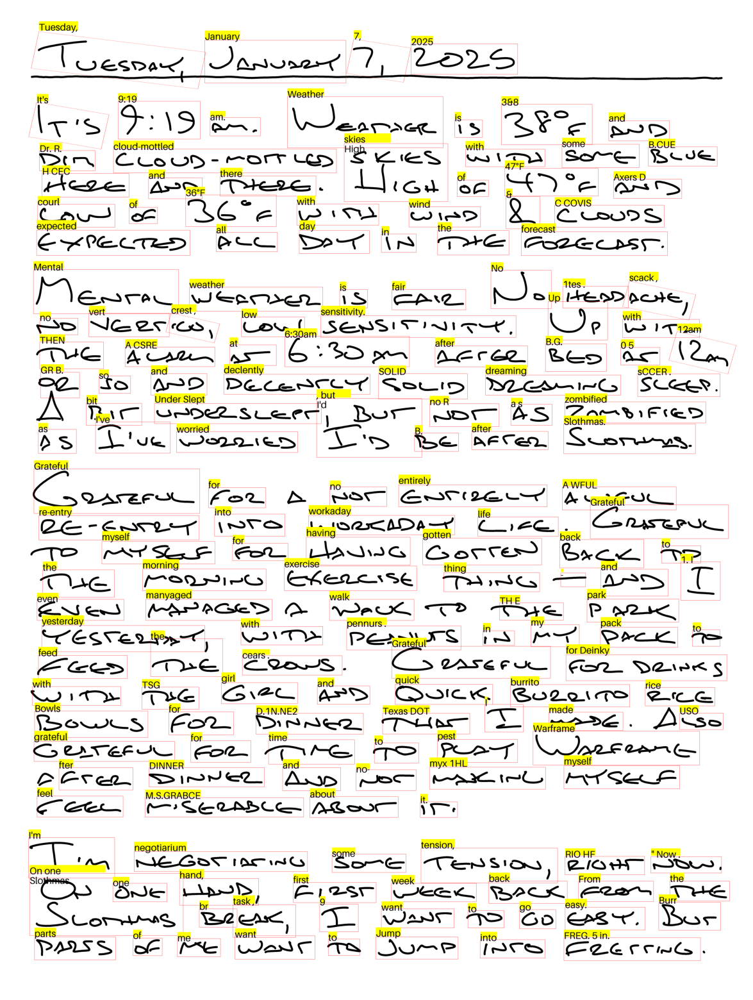

In [ ]:
# Visualize the predictions
visualize_predictions(image, sorted_bboxes, recognized_texts)
